# Kepler DR24 TCE — Dataset Exploration

## Objective

This notebook explores the Kepler Q1–Q17 DR24 Threshold Crossing Event (TCE) catalog as the labeled dataset for an exoplanet transit classification project.

The project aims to train a two-branch 1D Convolutional Neural Network (CNN) to distinguish planetary candidates from astrophysical false positives and non-transiting phenomena.

## Data Source

- NASA Exoplanet Archive
- Dataset: Kepler Q1–Q17 DR24 TCE
- Table: `q1_q17_dr24_tce`
- Retrieval method: Table Access Protocol (TAP)

## Notebook Objectives

- Retrieve the original TCE catalog.
- Examine dataset structure and column definitions.
- Analyze label distribution and class imbalance.
- Identify missing or invalid measurements.
- Prepare binary classification labels for subsequent experiments.

Each sample represents a candidate signal rather than an individual star.

### Dataset card
KEPLER DR24 TCE TABLE

Download: [NASA Exoplanet Archive, Q1 to Q17 DR24 TCE table](https://www.google.com/url?q=https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app%3DExoTbls%26config%3Dq1_q17_dr24_tce&sa=D&source=editors&ust=1795508212310466&usg=AOvVaw0XnOU0vq-Peka4NEKQlWOZ)

- A TCE (threshold-crossing event) is a repeating dip in a star's brightness that Kepler's pipeline flagged as a possible transit.
- Useful columns: kepid (the star), tce_period (days), tce_time0bk (time of the first transit, in days), tce_duration (hours) and av_training_set (the label).
- Labels: PC (planet candidate), AFP (astrophysical false positive, like an eclipsing binary star) and NTP (non-transiting phenomenon, like instrument noise). Rows labeled UNK or left empty have no usable label.
- Light curves: downloaded per star from NASA's MAST archive with lightkurve, one brightness measurement every 29.4 minutes.

## 0. Retrieving Raw Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.parse import urlencode

In [2]:
# NASA Exoplanet Archive TAP endpoint
base_url = (
    "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
)

query = "SELECT * FROM q1_q17_dr24_tce"

params = {
    "query": query,
    "format": "csv"
}

url = f"{base_url}?{urlencode(params)}"

# Download the catalog
df_raw = pd.read_csv(url)

# Create the raw data directory
data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

# Save the original dataset
file_path = data_dir / "kepler_dr24_tce.csv"
df_raw.to_csv(file_path, index=False)

print("Dataset shape:", df_raw.shape)
print("Saved to:", file_path)

df_raw.head()

Dataset shape: (20367, 158)
Saved to: ../data/raw/kepler_dr24_tce.csv


,ra,dec,tce_delivname,tce_datalink_dvr,tce_datalink_dvs,tce_nkoi,kepid,tce_plnt_num,tce_num_transits,tce_max_sngle_ev,...,tce_ptemp_stat,tce_cap_stat,tce_hap_stat,tce_rb_tpdur,tce_rb_tcount0,tce_rb_tcount1,tce_rb_tcount2,tce_rb_tcount3,tce_rb_tcount4,tce_rogue_flag
0,291.270040,36.85337,q1_q17_dr24_tce,001/001162/001162345/dv/kplr001162345-20141002...,001/001162/001162345/dv/kplr001162345-002-2014...,0,1162345,2,1609,4.959,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,290.749481,36.96238,q1_q17_dr24_tce,001/001292/001292087/dv/kplr001292087-20141002...,001/001292/001292087/dv/kplr001292087-002-2014...,0,1292087,2,1218,3.914,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,291.020981,36.90365,q1_q17_dr24_tce,001/001293/001293031/dv/kplr001293031-20141002...,001/001293/001293031/dv/kplr001293031-002-2014...,1,1293031,2,1200,7.494,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,291.270040,36.85337,q1_q17_dr24_tce,001/001162/001162345/dv/kplr001162345-20141002...,001/001162/001162345/dv/kplr001162345-003-2014...,0,1162345,3,1611,5.621,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,291.652650,36.89502,q1_q17_dr24_tce,001/001164/001164109/dv/kplr001164109-20141002...,001/001164/001164109/dv/kplr001164109-001-2014...,0,1164109,1,3,15.240,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Dataset Retrieval — Observations

The Kepler Q1–Q17 DR24 TCE catalog was successfully
retrieved from the NASA Exoplanet Archive using TAP.

The original dataset contains:
- 20,367 threshold-crossing events (TCEs).
- 158 catalog columns.

Each row represents a detected candidate signal rather
than an individual star. A single star may contain
multiple TCEs.

Only columns relevant to candidate identification,
transit preprocessing, baseline modeling, and target
labeling are selected for this experiment.

## 1. Dataset Structure and Initial Exploration

In [3]:
# Number of rows and columns
print("Shape:", df_raw.shape)

# Column names
print(df_raw.columns.tolist())

# Dataset information
df_raw.info()

Shape: (20367, 158)
['ra', 'dec', 'tce_delivname', 'tce_datalink_dvr', 'tce_datalink_dvs', 'tce_nkoi', 'kepid', 'tce_plnt_num', 'tce_num_transits', 'tce_max_sngle_ev', 'tce_max_mult_ev', 'tce_fwm_sra_err', 'tce_fwm_sra', 'tce_fwm_sdec_err', 'tce_fwm_sdec', 'tce_fwm_srao_err', 'tce_fwm_srao', 'tce_fwm_sdeco_err', 'tce_fwm_sdeco', 'tce_fwm_prao_err', 'tce_fwm_prao', 'tce_fwm_pdeco_err', 'tce_fwm_pdeco', 'tce_fwm_stat', 'tce_dicco_mdec_err', 'tce_dicco_mdec', 'tce_dicco_mra_err', 'tce_dicco_mra', 'tce_dicco_msky_err', 'tce_dicco_msky', 'tce_dikco_mdec_err', 'tce_dikco_mdec', 'tce_dikco_mra_err', 'tce_dikco_mra', 'tce_dikco_msky_err', 'tce_dikco_msky', 'tce_bin_oedp_stat', 'tce_full_conv', 'tce_limbdark_mod', 'tce_ldm_coeff4', 'tce_ldm_coeff3', 'tce_ldm_coeff2', 'tce_ldm_coeff1', 'tce_trans_mod', 'tce_model_snr', 'tce_model_dof', 'tce_model_chisq', 'tce_time0bk_err', 'tce_time0bk', 'tce_eccen_err', 'tce_eccen', 'tce_longp_err', 'tce_longp', 'tce_prad_err', 'tce_prad', 'tce_sma_err', 'tce_s

In [4]:
# Select the columns needed for our experiment

columns = [
    "kepid",
    "tce_plnt_num",
    "tce_period",
    "tce_time0bk",
    "tce_duration",
    "tce_depth",
    "av_training_set"
]

df = df_raw[columns].copy()

df.head(10)

,kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set
0,1162345,2,0.831850,132.227,2.392,6.092,AFP
1,1292087,2,1.095240,132.133,2.122,34.530,UNK
2,1293031,2,0.719273,132.227,1.521,29.680,UNK
3,1162345,3,0.831833,131.919,2.181,27.100,AFP
4,1164109,1,622.408000,162.256,12.010,161.300,UNK
5,757450,1,8.884920,134.452,2.078,16310.000,PC
6,892667,1,2.262110,132.171,7.509,29.410,NTP
7,892772,1,5.092600,133.451,3.399,246.500,AFP
8,1026032,1,8.460440,133.774,4.804,76500.000,UNK
9,1026032,2,4.230220,133.998,4.606,28810.000,UNK


### Missing Value Analysis

Missing values are examined in the selected catalog
columns to assess data completeness before preprocessing.

Complete transit parameters are important because
orbital period, transit epoch, and duration will be
used to align and transform stellar light curves.

In [5]:
# Inspect missing values

df.isna().sum()

kepid              0
tce_plnt_num       0
tce_period         0
tce_time0bk        0
tce_duration       0
tce_depth          0
av_training_set    0
dtype: int64

#### Observations

No missing values were detected in the seven selected
columns.

However, the absence of null values does not guarantee
that all measurements or labels are valid.

Additional validation is required to identify unusable
classification labels, invalid numerical values, and
duplicate candidate records.

### Original Label Distribution

The `av_training_set` column contains the Autovetter
training classifications assigned to candidate signals.

The original label distribution is examined to understand
the available classification categories and potential
class imbalance.

The four observed categories are:
- PC: Planet Candidate
- AFP: Astrophysical False Positive
- NTP: Non-Transiting Phenomenon
- UNK: Unknown

In [6]:
# Examine the original label distribution

df["av_training_set"].value_counts(dropna=False)

av_training_set
AFP    9596
UNK    4630
PC     3600
NTP    2541
Name: count, dtype: int64

#### Observations

The original dataset contains:
- AFP: 9,596 signals
- UNK: 4,630 signals
- PC: 3,600 signals
- NTP: 2,541 signals

The distribution is imbalanced, with astrophysical
false positives representing the largest category.

Unknown signals are excluded from supervised training
because they do not have a usable target classification.

After excluding UNK, 15,737 labeled TCEs remain.

### Binary Classification Label Preparation

Following the original Exoplanet Finder methodology,
the multiclass catalog labels are converted into a
binary classification target.

- PC is mapped to 1 (planet candidate).
- AFP and NTP are mapped to 0 (negative class).
- UNK is excluded from supervised learning.

#### Observations

The resulting dataset contains 15,737 labeled TCEs:
- Positive class: 3,600 samples (22.88%).
- Negative class: 12,137 samples (77.12%).

The dataset exhibits significant class imbalance,
with approximately 3.37 negative samples for every
positive sample.

Accuracy alone may therefore provide a misleading
assessment of model performance. ROC-AUC, precision,
recall, and precision-recall curves will be used
during model evaluation.

In [7]:
# Prepare binary classification labels

valid_labels = ["PC", "AFP", "NTP"]

# Keep only labeled samples
df = df[df["av_training_set"].isin(valid_labels)].copy()

# Create binary target
label_map = {
    "PC": 1,
    "AFP": 0,
    "NTP": 0
}

df["label"] = df["av_training_set"].map(label_map)

print("Number of labeled TCEs:", len(df))
print("Number of unique stars:", df["kepid"].nunique())

df.head()

Number of labeled TCEs: 15737
Number of unique stars: 9865


,kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set,label
0,1162345,2,0.831850,132.227,2.392,6.092,AFP,0
3,1162345,3,0.831833,131.919,2.181,27.100,AFP,0
5,757450,1,8.884920,134.452,2.078,16310.000,PC,1
6,892667,1,2.262110,132.171,7.509,29.410,NTP,0
7,892772,1,5.092600,133.451,3.399,246.500,AFP,0


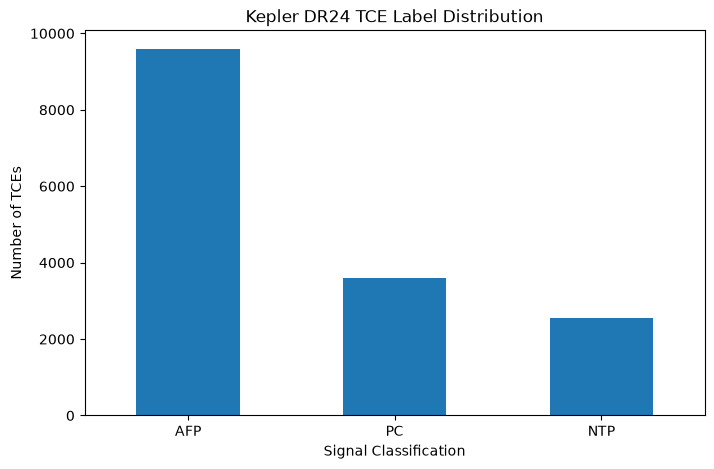

In [8]:
# Visualize the actual distribution

fig, ax = plt.subplots(figsize=(8, 5))

df["av_training_set"].value_counts().plot(
    kind="bar",
    ax=ax
)

ax.set_title("Kepler DR24 TCE Label Distribution")
ax.set_xlabel("Signal Classification")
ax.set_ylabel("Number of TCEs")

plt.xticks(rotation=0)
plt.show()

In [9]:
# check the binary distribution

print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))

label
0    12137
1     3600
Name: count, dtype: int64
label
0    0.77124
1    0.22876
Name: proportion, dtype: float64


### Star-Level and Candidate-Level Analysis

A single star may contain multiple threshold-crossing
events. Therefore, the number of candidate signals
may exceed the number of unique stars.

This relationship is examined to determine how
candidate records should be grouped during dataset
splitting and light-curve retrieval.

In [13]:
# Count candidate signals per star
tce_per_star = df.groupby("kepid").size()

print("Total TCEs:", len(df))
print("Unique stars:", df["kepid"].nunique())
print("Average TCEs per star:", tce_per_star.mean())
print("Maximum TCEs per star:", tce_per_star.max())
print("Stars with multiple TCEs:", (tce_per_star > 1).sum())

tce_per_star.describe()

Total TCEs: 15737
Unique stars: 9865
Average TCEs per star: 1.5952356817029905
Maximum TCEs per star: 8
Stars with multiple TCEs: 4360


count    9865.000000
mean        1.595236
std         0.796050
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
dtype: float64

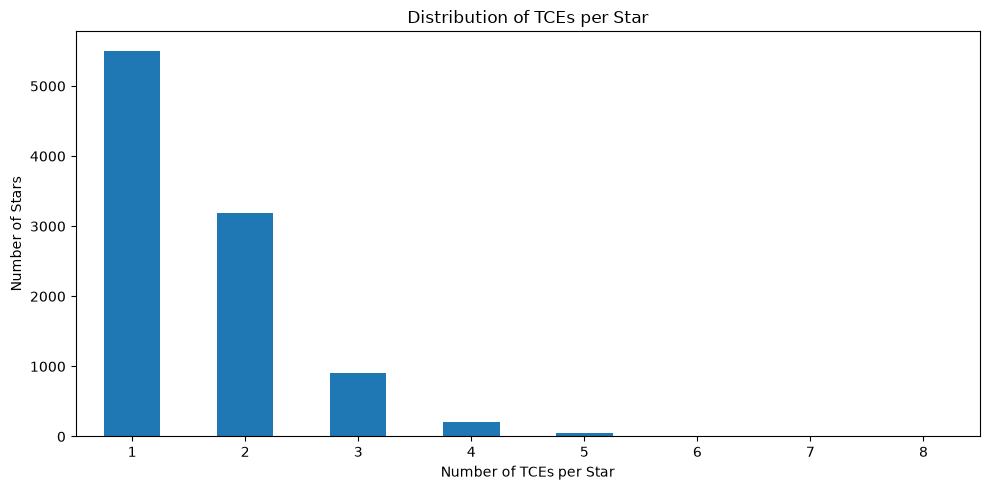

In [14]:
# Visualize the distribution

fig, ax = plt.subplots(figsize=(10, 5))

tce_per_star.value_counts().sort_index().plot(
    kind="bar",
    ax=ax
)

ax.set_title("Distribution of TCEs per Star")
ax.set_xlabel("Number of TCEs per Star")
ax.set_ylabel("Number of Stars")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Observations

The filtered dataset contains 15,737 labeled TCEs
associated with 9,865 unique stars, corresponding
to approximately 1.60 candidate signals per star.

Multiple TCEs from the same star share the underlying
stellar light curve, including its noise characteristics
and stellar variability.

This dependency must be considered when constructing
training, validation, and testing datasets to prevent
information leakage between dataset partitions.

## 2. Data Validation and Export

Before dataset splitting, the selected catalog fields
are validated to identify duplicate candidate records,
non-finite measurements, and physically invalid
transit parameters.

The validated labeled dataset is exported for use in
subsequent preprocessing and model development.

In [15]:
# Check duplicate candidate identifiers
duplicate_count = df.duplicated(
    subset=["kepid", "tce_plnt_num"]
).sum()

print("Duplicate TCE records:", duplicate_count)

# Check numerical values
numeric_columns = [
    "tce_period",
    "tce_time0bk",
    "tce_duration",
    "tce_depth"
]

print("\nNon-finite numerical values:")
print((~np.isfinite(df[numeric_columns])).sum())

# Check physical validity
print("\nInvalid orbital periods:",
      (df["tce_period"] <= 0).sum())

print("Invalid transit durations:",
      (df["tce_duration"] <= 0).sum())

print("Non-positive transit depths:",
      (df["tce_depth"] <= 0).sum())

print("Duration greater than or equal to period:",
      (df["tce_duration"] / 24 >= df["tce_period"]).sum())

Duplicate TCE records: 0

Non-finite numerical values:
tce_period      0
tce_time0bk     0
tce_duration    0
tce_depth       0
dtype: int64

Invalid orbital periods: 0
Invalid transit durations: 0
Non-positive transit depths: 1
Duration greater than or equal to period: 0


In [16]:
# If the validation checks are clean, save the dataset

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "kepler_dr24_tce_labeled.csv"

df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", df.shape)

Saved to: ../data/processed/kepler_dr24_tce_labeled.csv
Dataset shape: (15737, 8)
